Plott for ulike corners fra simuleringen    

In [81]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NAME_RE = re.compile(rb"(sweep|time|frequency|[vi]\([^()\s]*\))")
TITLE_RE = re.compile(rb"\d+:\*")

def _parse_run(raw):
    n = len(raw)
    names = []
    for m in NAME_RE.finditer(raw[:8192]):
        s = m.group(1).decode()
        if s not in names:
            names.append(s)
    if not names:
        return None
    last = max(m.end() for m in NAME_RE.finditer(raw[:8192]))
    nv = len(names); row = 8 * nv
    for off in range(last, min(last + 1024, n)):
        if (n - off) % row:
            continue
        rows = (n - off) // row
        if rows < 3:
            continue
        d = np.frombuffer(raw, dtype="<f8", count=rows*nv, offset=off).reshape(rows, nv)
        if not np.all(np.isfinite(d)) or np.abs(d).max() > 1e3:
            continue
        if np.all(np.diff(d[:, 0]) > 0):
            return pd.DataFrame(d, columns=names)
    return None

def read_aimspice_out(path, run=-1):
    """run=-1 gir siste (nyeste) kjøring hvis fila inneholder flere."""
    raw = open(path, "rb").read()
    starts = []
    for m in TITLE_RE.finditer(raw):
        s = m.start() - 4
        if s < 0:
            continue
        L = int.from_bytes(raw[s:s+4], "little")
        title = raw[m.start():m.start()+L]
        if 3 < L < 200 and all(32 <= c < 127 for c in title):
            starts.append(s)
    starts = starts or [0]
    bounds = starts + [len(raw)]
    runs = [df for a, b in zip(bounds, bounds[1:])
            if (df := _parse_run(raw[a:b])) is not None]
    if not runs:
        raise ValueError(f"Fant ikke datablokken i {path}")
    print(f"{path}: {len(runs)} kjøring(er), bruker nr. {len(runs)+run+1 if run < 0 else run+1}")
    return runs[run]

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

dc sweep tt

frontend_dc_sweep.out: 1 kjøring(er), bruker nr. 1


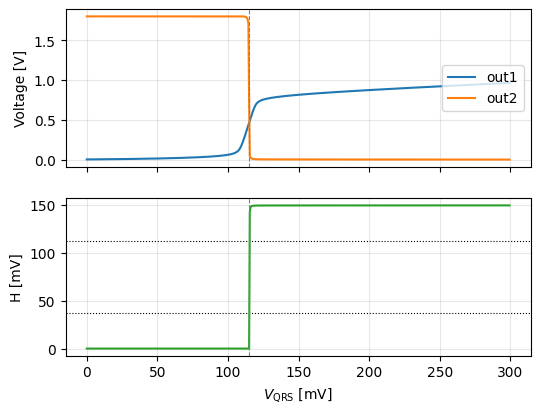

In [82]:
df = read_aimspice_out("frontend_dc_sweep.out")
x = df["sweep"] * 1e3
fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(6, 4.5))
a1.plot(x, df["v(out1)"], label="out1")
a1.plot(x, df["v(out2)"], label="out2")
a1.set_ylabel("Voltage [V]"); a1.legend(loc="center right")
a2.plot(x, df["v(h)"] * 1e3, color="C2")
a2.axhline(37.5, ls=":", color="k", lw=0.8)
a2.axhline(112.5, ls=":", color="k", lw=0.8)
a2.set_ylabel("H [mV]"); a2.set_xlabel(r"$V_\mathrm{QRS}$ [mV]")
for a in (a1, a2):
    a.axvline(115, ls="--", color="gray", lw=0.8)
plt.show()

fine sweep for tt ss ff:

frontend_dc_sweep_precise.out: 4 kjøring(er), bruker nr. 4
frontend_dc_sweep_precise_ss.out: 1 kjøring(er), bruker nr. 1
frontend_dc_sweep_precise_ff.out: 1 kjøring(er), bruker nr. 1


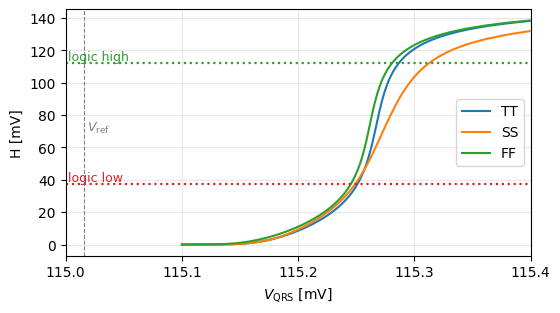

In [83]:
fine = {"TT": "frontend_dc_sweep_precise.out",
        "SS": "frontend_dc_sweep_precise_ss.out",
        "FF": "frontend_dc_sweep_precise_ff.out"}

fig, ax = plt.subplots(figsize=(6, 3.2))
for lab, f in fine.items():
    d = read_aimspice_out(f)
    ax.plot(d["sweep"] * 1e3, d["v(h)"] * 1e3, label=lab)

ax.axhline(37.5, ls=":", color="tab:red", lw=1.6)
ax.axhline(112.5, ls=":", color="tab:green", lw=1.6)
ax.text(115.002, 39, "logic low", fontsize=9, color="tab:red")
ax.text(115.002, 114, "logic high", fontsize=9, color="tab:green")

ax.axvline(115.016, ls="--", color="gray", lw=0.8)
ax.text(115.018, 70, r"$V_\mathrm{ref}$", fontsize=9, color="gray")

ax.set_xlim(115.0, 115.4)
ax.set_xticks([115.0, 115.1, 115.2, 115.3, 115.4])
ax.set_xlabel(r"$V_\mathrm{QRS}$ [mV]")
ax.set_ylabel("H [mV]")
ax.legend(loc="center right")
plt.show()

heartbeat for tt

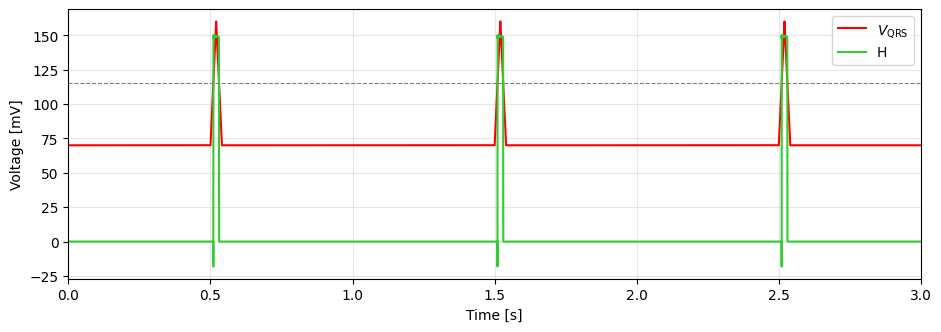

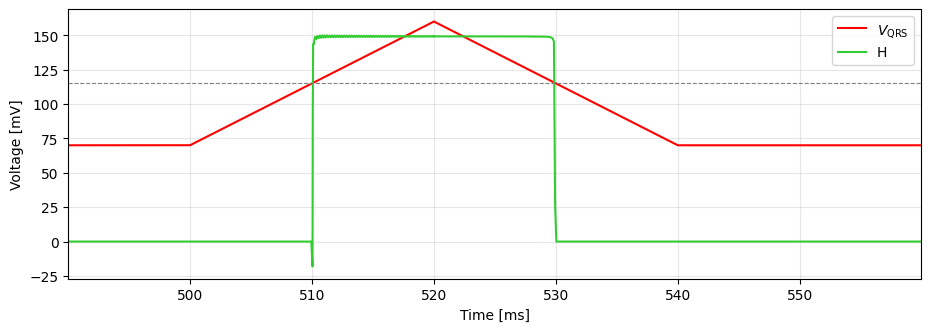

In [84]:
def plot_hb(t0, t1, ms=False):
    d = hb[(hb["time"] >= t0) & (hb["time"] <= t1)]
    t = d["time"] * (1e3 if ms else 1)
    fig, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(t, d["v(qrs)"] * 1e3, color="red", label=r"$V_\mathrm{QRS}$")
    ax.plot(t, d["v(h)"] * 1e3, color="limegreen", label="H")
    ax.axhline(115, ls="--", color="gray", lw=0.8)
    ax.set_xlabel("Time [ms]" if ms else "Time [s]")
    ax.set_ylabel("Voltage [mV]")
    ax.set_xlim(t.iloc[0], t.iloc[-1])
    ax.legend(loc="upper right")
    plt.show()


plot_hb(0, 3)
plot_hb(0.49, 0.56, ms=True)

Plots for simulering av PACE    

Fant: []


/var/folders/0r/k8vf_smj5sb34gnq8jlbf_nr0000gn/T/ipykernel_30010/4189828611.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.set_xlim(0, 5); ax.legend(loc="upper right", fontsize=8)


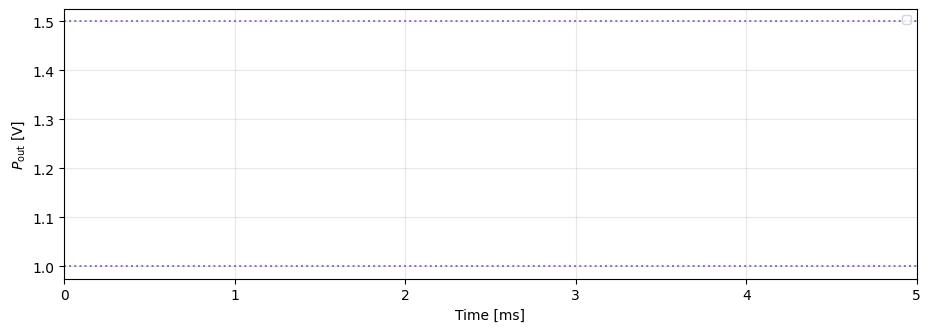

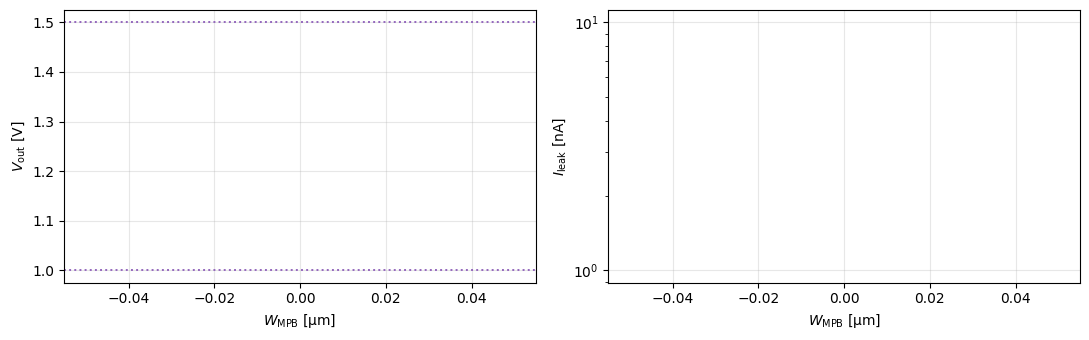

In [85]:
import glob, re

# finn filene og les W fra filnavnet
runs = []
for f in glob.glob("*.out"):
    m = re.search(r"(\d+(?:\.\d+)?)u", f)
    if m:
        runs.append((float(m.group(1)), f))
runs.sort()
print("Fant:", runs)

Ws, Vouts, Ileaks = [], [], []
fig, ax = plt.subplots(figsize=(11, 3.5))
for W, f in runs:
    d = read_aimspice_out(f)
    t = d["time"]
    ax.plot(t * 1e3, d["v(pout)"], label=f"W = {W:g} µm")
    Ws.append(W)
    Vouts.append(d["v(pout)"][(t > 1.5e-3) & (t < 2.5e-3)].mean())
    Ileaks.append(abs(d["i(vddh)"][(t > 4e-3) & (t < 5e-3)].mean()))
ax.axhline(1.0, ls=":", color="tab:purple", lw=1.4)
ax.axhline(1.5, ls=":", color="tab:purple", lw=1.4)
ax.set_xlabel("Time [ms]"); ax.set_ylabel(r"$P_\mathrm{out}$ [V]")
ax.set_xlim(0, 5); ax.legend(loc="upper right", fontsize=8)
plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(Ws, Vouts, "o-")
a1.axhline(1.0, ls=":", color="tab:purple", lw=1.4)
a1.axhline(1.5, ls=":", color="tab:purple", lw=1.4)
a1.set_xlabel(r"$W_\mathrm{MPB}$ [µm]"); a1.set_ylabel(r"$V_\mathrm{out}$ [V]")
a2.semilogy(Ws, [i * 1e9 for i in Ileaks], "o-", color="C1")
a2.set_xlabel(r"$W_\mathrm{MPB}$ [µm]"); a2.set_ylabel(r"$I_\mathrm{leak}$ [nA]")
plt.tight_layout(); plt.show()

for W, V, I in zip(Ws, Vouts, Ileaks):
    print(f"W = {W:5g} µm   Vout = {V:.3f} V   Ileak = {I*1e9:.3f} nA")